### The modes of a Jordan + TopK KAE on CLIP

The KAE stands in for CLIP ViT-B/32's blocks 7 to 12: it encodes the CLS token after block 6, applies K once, and decodes a prediction of the CLS token after block 12. CLIP's own last layers and zero-shot classifier then read that prediction as if it were the real block 12.

`im_jordan256_2k_both`:
- K is in real Jordan form: one real eigenvalue and 1024 blocks `[[a, -b], [b, a]]`. Each block is one mode, with eigenvalues `a ± ib`.
- TopK keeps the 128 largest of the 1025 modes for each image and zeroes the rest.
- Trained on 3 augmented views of ImageNet, with reconstruction, prediction, isometry, and two losses read through CLIP's last layers: the cosine between final embeddings, and the KL between zero-shot class probabilities.
- Checkpoint from its best epoch, about 10. Training stopped at epoch 12.

Dampening a mode means scaling its eigenvalue: we multiply `a` and `b` of one block of K by `alpha`. Nothing else changes.

In [1]:
import copy
import os
import sys
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import open_clip
import pandas as pd
import torch
from datasets import load_dataset
from dotenv import load_dotenv
from PIL import Image
from safetensors.torch import load_file
from sklearn.decomposition import PCA
from sklearn.metrics import roc_auc_score

sys.path.insert(0, "../scripts/tokae")
from train import JordanKoopmanAutoencoder

load_dotenv("../.env")
torch.set_grad_enabled(False)
torch.manual_seed(0)
pd.set_option("display.width", 200)

NAME = "im_jordan256_2k_both"
SNOW_MODE = 903
ALPHAS = [0.0, 0.25, 0.5, 0.75, 1.0, 1.25, 1.5, 1.75, 2.0]
NUM_RANDOM = 6

# NOTE: Picked by eye after looking at the top images of 36 modes. A random sample comes after.
SHOWCASE = {
    903: "snow",
    878: "old black-and-white photos",
    647: "sepia",
    818: "motion blur",
    281: "mesh and fences",
    271: "people playing music",
    310: "stripes",
    94: "monarch butterflies",
}
SNOW_FOLDERS = {
    "armytank": 847,
    "carwheel": 479,
    "firetruck": 555,
    "motorscooter": 670,
    "racingcar": 751,
    "schoolbus": 779,
    "trafficlight": 920,
}

BLUE, ORANGE, MUTED, INK = "#2a78d6", "#eb6834", "#898781", "#52514e"
plt.rcParams.update(
    {
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.edgecolor": MUTED,
        "axes.labelcolor": INK,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "axes.grid": True,
        "grid.color": "#e8e7e3",
        "grid.linewidth": 0.6,
        "legend.frameon": False,
    }
)

/tmp/claude-1001/-home-dunstan-git-koopmann/0bba89b8-c8c4-41c4-a0d8-5b331c6750fd/scratchpad/venv/lib/python3.11/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


##### Model and data

States are standardized with the statistics the model was trained with. Activity is the size of a mode's coefficient, and TopK leaves most of them at exactly zero.

In [2]:
save_dir = Path(os.getenv("WEIGHTS_CACHE")) / "tokae"
root = Path(os.getenv("DATASETS_CACHE"))
stats = torch.load(save_dir / f"{NAME}_stats.pt")

kae = JordanKoopmanAutoencoder(
    top_k=256,
    in_features=768,
    latent_features=2049,
    hidden_config=[2048],
    bias=True,
    batchnorm=False,
    nonlinearity="leaky_relu",
)
kae.load_state_dict(load_file(save_dir / f"{NAME}.safetensors"))
kae.eval()

# shape: [modes]. Mode 0 is the real eigenvalue, mode m > 0 is the block on latent coordinates 2m - 1 and 2m
eigenvalues = torch.cat([kae.real_eigenvalue.to(torch.cfloat), torch.complex(kae.block_real, kae.block_imag)])


def predict(model, start):
    """The KAE's prediction of block 12 from block 6, both standardized."""

    return model.decode(model.koopman_forward(model.encode(start), 1))


def get_activity(start):
    """How strongly each mode is on for each image."""

    phi = kae.encode(start)
    return torch.cat([phi[:, :1].abs(), phi[:, 1:].unflatten(-1, (-1, 2)).norm(dim=-1)], dim=-1)


def dampen(mode, alpha):
    """A copy of the KAE whose K has one eigenvalue scaled by alpha."""

    edited = copy.deepcopy(kae)
    if mode == 0:
        edited.real_eigenvalue.mul_(alpha)
    else:
        edited.block_real[mode - 1].mul_(alpha)
        edited.block_imag[mode - 1].mul_(alpha)
    return edited


# shape: [images, 2, 768], the CLS token after blocks 6 and 12
val = torch.load(root / "imagenet" / "clip_cls_ViT-B-32_val_blocks_5_11.pt")
val_x, val_y = (val["states"] - stats["mean"]) / stats["std"], val["labels"]
images = load_dataset("ILSVRC/imagenet-1k", split="validation", cache_dir=os.getenv("DATASETS_CACHE"))
class_names = open_clip.IMAGENET_CLASSNAMES

# shape: [images, modes]
activity = torch.cat([get_activity(batch) for batch in val_x[:, 0].split(5_000)])
usage = (activity > 0).double().mean(dim=0)

##### CLIP's last layers

`embed` turns a block 12 state into CLIP's final image embedding. The zero-shot classifier compares it with the text of ImageNet's 1000 classes, and the snow score is the embedding along "a photo in the snow" minus "a photo".

In [3]:
clip, _, preprocess = open_clip.create_model_and_transforms(
    "ViT-B-32",
    pretrained="openai",
    force_quick_gelu=True,  # OpenAI's weights were trained with QuickGELU
    cache_dir=f"{os.getenv('HF_HOME')}/open_clip",
)
clip.eval()
tokenizer = open_clip.get_tokenizer("ViT-B-32")

head_path = save_dir / "zero_shot_head_ViT-B-32.pt"
if not head_path.exists():
    head = open_clip.build_zero_shot_classifier(
        clip, tokenizer, open_clip.IMAGENET_CLASSNAMES, open_clip.OPENAI_IMAGENET_TEMPLATES, device="cpu"
    )
    torch.save(head, head_path)
head = torch.load(head_path)


def embed(states):
    out = clip.visual.ln_post(states * stats["std"] + stats["mean"]) @ clip.visual.proj
    return out / out.norm(dim=-1, keepdim=True)


def classify(states):
    return (embed(states) @ head).argmax(dim=-1)


def embed_text(prompt):
    out = clip.encode_text(tokenizer([prompt]))[0]
    return out / out.norm()


snow_direction = embed_text("a photo in the snow") - embed_text("a photo")
snow_direction = snow_direction / snow_direction.norm()

##### Prediction

Zero-shot accuracy on ImageNet's 50,000 validation images, and how often the KAE gives the same answer as CLIP, right or wrong.

In [4]:
true_answers = classify(val_x[:, 1])
answers = torch.cat([classify(predict(kae, batch)) for batch in val_x[:, 0].split(5_000)])

pd.DataFrame(
    {
        "CLIP": {"zero-shot accuracy": (true_answers == val_y).double().mean().item(), "agrees with CLIP": 1.0},
        "KAE": {
            "zero-shot accuracy": (answers == val_y).double().mean().item(),
            "agrees with CLIP": (answers == true_answers).double().mean().item(),
        },
    }
).T.round(3)

,zero-shot accuracy,agrees with CLIP
CLIP,0.633,1.000
KAE,0.390,0.443


##### The spectrum

One eigenvalue per mode. Each block also has the conjugate `a - ib`, so we plot the upper half only. Dot size is how often TopK keeps the mode. With one step from block 6 to block 12, an eigenvalue is a gain and a rotation applied once.

983 of 1025 modes are ever kept, 2 with |eigenvalue| > 2 are off the plot


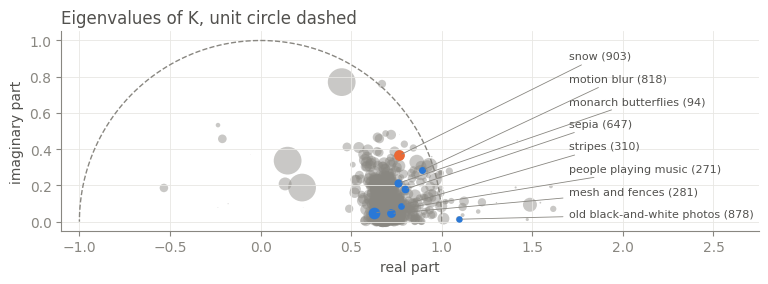

In [5]:
shown = eigenvalues[eigenvalues.abs() < 2]
print(f"{int((usage > 0).sum())} of {len(eigenvalues)} modes are ever kept, {len(eigenvalues) - len(shown)} with |eigenvalue| > 2 are off the plot")

fig, ax = plt.subplots(figsize=(9, 3.6))
circle = np.exp(1j * np.linspace(0, np.pi, 200))
ax.plot(circle.real, circle.imag, color=MUTED, lw=1, ls="--")
keep = eigenvalues.abs() < 2
ax.scatter(eigenvalues.real[keep].numpy(), eigenvalues.imag[keep].abs().numpy(), s=400 * usage[keep].numpy(), color=MUTED, alpha=0.45, lw=0)
# NOTE: Labels sit in a column on the right, ordered like their modes, so they don't cover the cluster
order = sorted(SHOWCASE, key=lambda mode: abs(eigenvalues[mode].imag.item()))
for slot, mode in enumerate(order):
    real, imag = eigenvalues[mode].real.item(), abs(eigenvalues[mode].imag.item())
    color = ORANGE if mode == SNOW_MODE else BLUE
    ax.scatter(real, imag, s=max(400 * usage[mode].item(), 12), color=color, lw=0, zorder=3)
    ax.annotate(
        f"{SHOWCASE[mode]} ({mode})",
        xy=(real, imag),
        xytext=(1.7, 0.04 + 0.125 * slot),
        fontsize=8,
        color=INK,
        va="center",
        arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.6),
    )
ax.set_xlim(-1.1, 2.75)
ax.set_xlabel("real part")
ax.set_ylabel("imaginary part")
ax.set_aspect("equal")
ax.set_title("Eigenvalues of K, unit circle dashed", loc="left", color=INK)
plt.show()

##### What some modes fire on

The 8 validation images where each mode is most active, with their ImageNet class underneath. Most of these modes cut across classes.

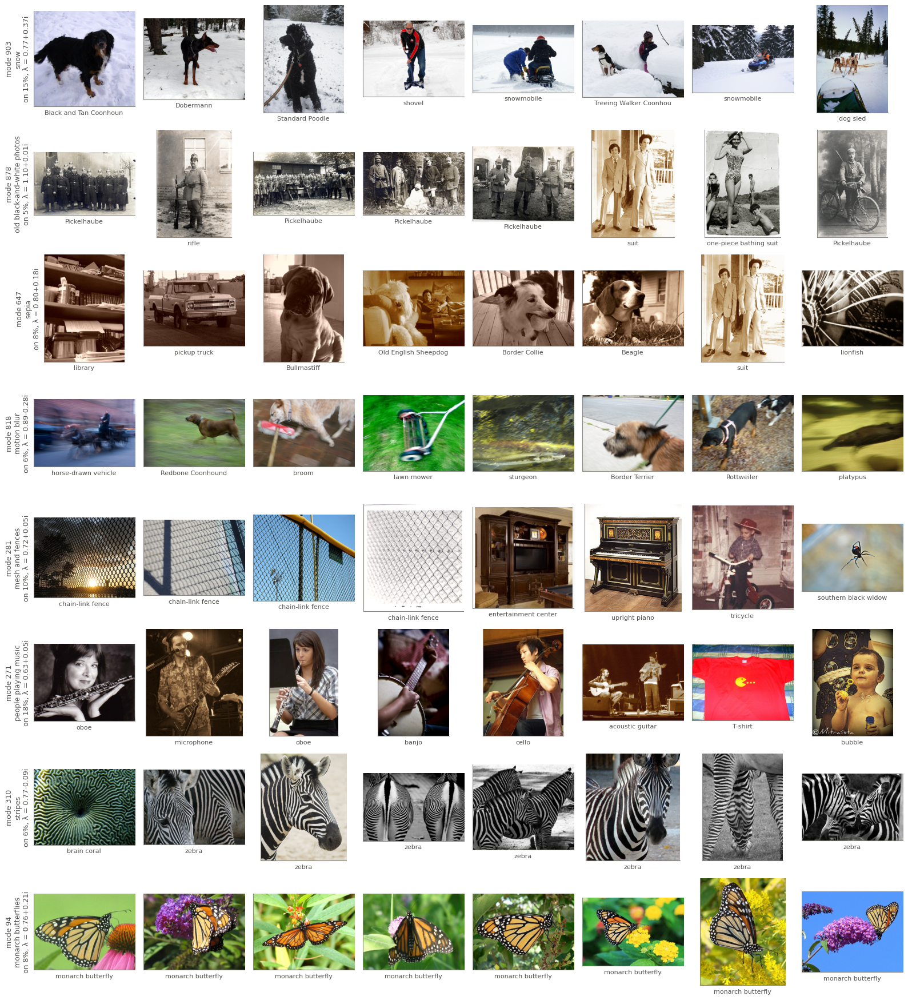

In [6]:
def show_modes(modes, labels):
    fig, axes = plt.subplots(len(modes), 8, figsize=(16, 2.2 * len(modes)))
    for row, mode, label in zip(axes, modes, labels):
        for ax, index in zip(row, activity[:, mode].topk(8).indices.tolist()):
            image = images[index]["image"].convert("RGB")
            image.thumbnail((256, 256))
            ax.imshow(np.asarray(image))
            ax.set_xticks([])
            ax.set_yticks([])
            ax.grid(False)
            ax.set_xlabel(class_names[val_y[index]][:22], fontsize=8, color=INK)
        real, imag = eigenvalues[mode].real.item(), eigenvalues[mode].imag.item()
        row[0].set_ylabel(
            f"mode {mode}\n{label}\non {usage[mode].item():.0%}, λ = {real:.2f}{imag:+.2f}i",
            fontsize=9,
            color=INK,
        )
    fig.tight_layout()
    plt.show()


show_modes(list(SHOWCASE), list(SHOWCASE.values()))

Modes drawn at random from those kept on at least 1% of images, so that the gallery above isn't only our best picks. Random here is how they were chosen, not what they mean: most still have a clear theme, such as sea animals in water, large black objects, reptiles on gravel, and dark venues.

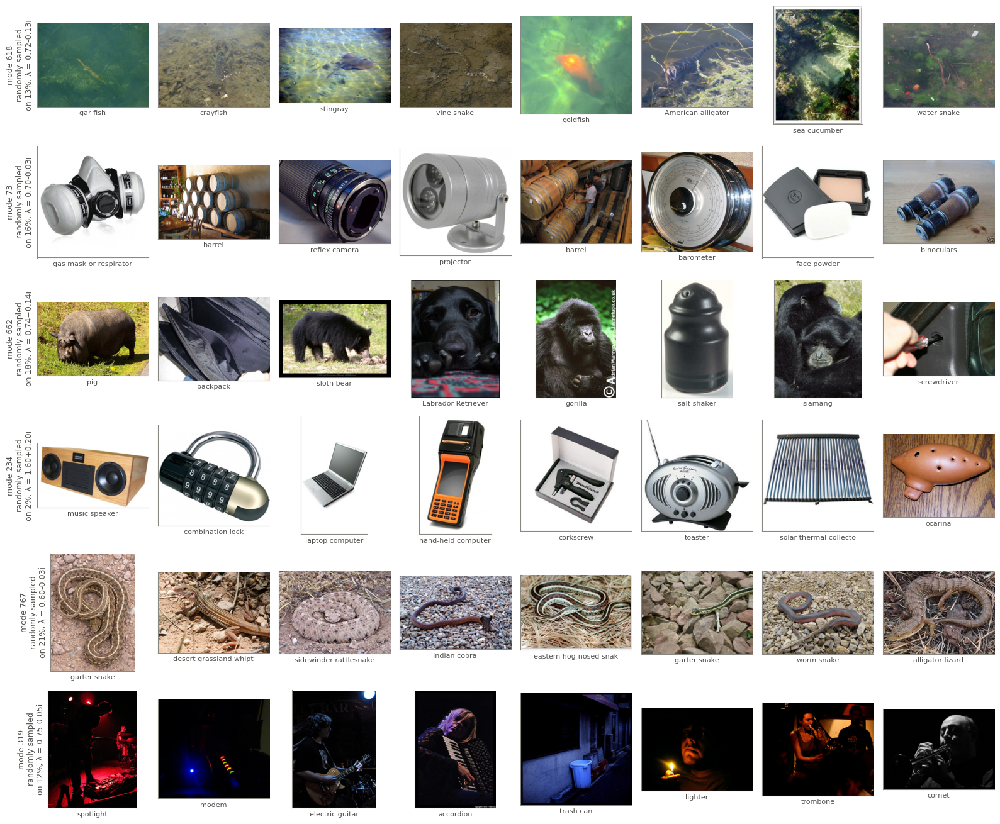

In [7]:
candidates = (usage >= 0.01).nonzero()[:, 0]
sample = candidates[torch.randperm(len(candidates))[:NUM_RANDOM]].tolist()
show_modes(sample, ["randomly sampled"] * NUM_RANDOM)

##### How many modes are coherent?

A rough check over every mode kept on at least 1% of images. We take each mode's top 16 validation images and measure how alike they are in CLIP's final embedding space: the mean cosine between pairs. A mode passes if it beats 99% of random sets of 16 images.

This is a low bar: 16 images of one class score far higher. It also misses some modes that look coherent by eye, such as mesh and fences (281) and people playing music (271). So passing means "more alike than chance", not "interpretable".

Random sets of 16: 99th percentile 0.541. Sets of 16 from one class: median 0.709
85% of 961 modes beat random
Mesh and fences 0.517, people playing music 0.441


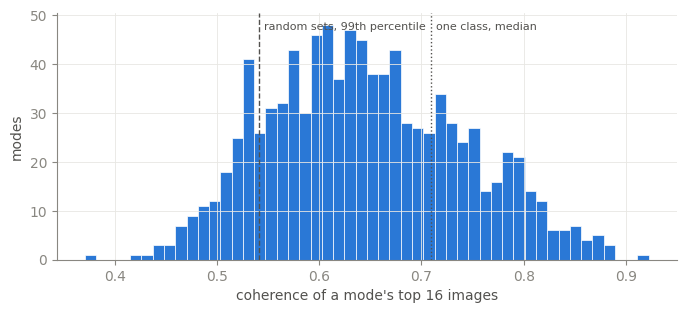

,modes,beat_random
kind,,
1-3 classes,61,1.000
4-8 classes,263,0.954
9-16 classes,637,0.799


In [8]:
true_embeddings = torch.cat([embed(batch) for batch in val_x[:, 1].split(5_000)])


def get_coherence(indices):
    """Mean cosine between the CLIP embeddings of a set of images, leaving out each image with itself."""

    similarity = true_embeddings[indices] @ true_embeddings[indices].T
    n = len(indices)
    return ((similarity.sum() - n) / (n * (n - 1))).item()


random_sets = np.array([get_coherence(torch.randperm(len(val_y))[:16]) for _ in range(1_000)])
class_sets = np.array([get_coherence((val_y == c).nonzero()[:, 0][:16]) for c in range(1_000)])
threshold = np.quantile(random_sets, 0.99)

rows = []
for mode in candidates.tolist():
    top = activity[:, mode].topk(16).indices
    rows.append({"mode": mode, "coherence": get_coherence(top), "classes in top 16": len(set(val_y[top].tolist()))})
coherence = pd.DataFrame(rows).set_index("mode")
coherence["kind"] = pd.cut(coherence["classes in top 16"], [0, 3, 8, 16], labels=["1-3 classes", "4-8 classes", "9-16 classes"])

print(f"Random sets of 16: 99th percentile {threshold:.3f}. Sets of 16 from one class: median {np.median(class_sets):.3f}")
print(f"{(coherence['coherence'] > threshold).mean():.0%} of {len(coherence)} modes beat random")
print(f"Mesh and fences {coherence.loc[281, 'coherence']:.3f}, people playing music {coherence.loc[271, 'coherence']:.3f}")

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(coherence["coherence"], bins=50, color=BLUE, edgecolor="white", linewidth=0.5)
for value, label, style in [(threshold, "random sets, 99th percentile", "--"), (np.median(class_sets), "one class, median", ":")]:
    ax.axvline(value, color=INK, lw=1, ls=style)
    ax.annotate(label, (value, ax.get_ylim()[1]), xytext=(4, -12), textcoords="offset points", fontsize=8, color=INK)
ax.set_xlabel("coherence of a mode's top 16 images")
ax.set_ylabel("modes")
plt.show()

coherence.groupby("kind", observed=True)["coherence"].agg(modes="size", beat_random=lambda c: (c > threshold).mean()).round(3)

##### Finding the snow mode

129 photos of vehicles in snow ([Santurkar et al.](https://arxiv.org/abs/2112.01008)), against the 350 normal validation images of the same 7 classes. We score each mode by how well its activity alone separates snowy from normal images (AUC). CLIP gets the snowy images right far less often than the normal ones.

In [9]:
paths = sorted((root / "snowy_imagenet").glob("*/*.jpg"))
states = []
hooks = [
    clip.visual.transformer.resblocks[block].register_forward_hook(lambda _, __, output: states.append(output[:, 0]))
    for block in stats["blocks"]
]
clip.encode_image(torch.stack([preprocess(Image.open(path)) for path in paths]))
for hook in hooks:
    hook.remove()

snowy_x = (torch.stack(states, dim=1) - stats["mean"]) / stats["std"]
snowy_y = torch.tensor([SNOW_FOLDERS[path.parent.name] for path in paths])

normal = torch.isin(val_y, torch.tensor(list(SNOW_FOLDERS.values())))
x, y = torch.cat([val_x[normal], snowy_x]), torch.cat([val_y[normal], snowy_y])
is_snowy = torch.cat([torch.zeros(int(normal.sum()), dtype=torch.bool), torch.ones(len(snowy_x), dtype=torch.bool)])

snow_activity = get_activity(x[:, 0])
aucs = torch.tensor([roc_auc_score(is_snowy.numpy(), snow_activity[:, mode].numpy()) for mode in range(len(eigenvalues))])

true_correct = classify(x[:, 1]) == y
print(f"CLIP: snowy {true_correct[is_snowy].double().mean():.3f}, normal {true_correct[~is_snowy].double().mean():.3f}")
pd.DataFrame(
    {
        "AUC": aucs.numpy(),
        "on for snowy": (snow_activity[is_snowy] > 0).double().mean(dim=0).numpy(),
        "on for normal": (snow_activity[~is_snowy] > 0).double().mean(dim=0).numpy(),
    }
).sort_values("AUC", ascending=False).head(5).round(3)

CLIP: snowy 0.535, normal 0.643


,AUC,on for snowy,on for normal
903,0.950,0.930,0.186
633,0.900,0.837,0.109
776,0.827,0.713,0.109
309,0.757,1.000,1.000
845,0.730,0.589,0.197


##### Dampening the snow eigenvalue

We scale the snow mode's eigenvalue by `alpha` and read the prediction with CLIP's zero-shot classifier. `alpha = 1` is K as trained, `alpha = 0` removes the mode, and `alpha > 1` excites it. The dotted lines are real CLIP.

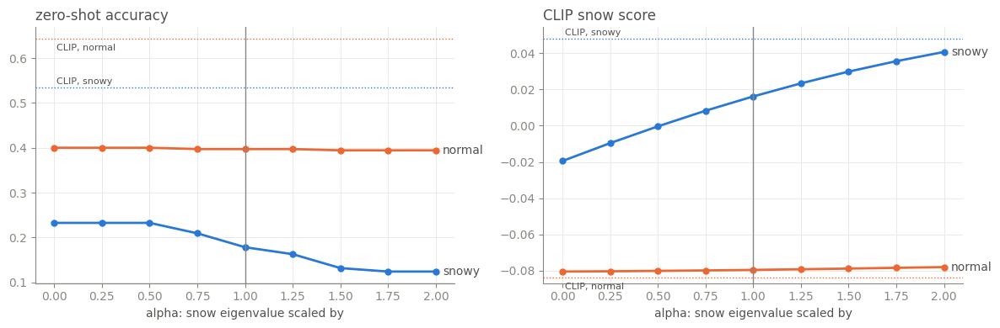

,"accuracy, snowy","accuracy, normal","snow score, snowy","snow score, normal"
alpha,,,,
0.00,0.233,0.400,-0.020,-0.081
0.25,0.233,0.400,-0.010,-0.080
0.50,0.233,0.400,-0.000,-0.080
0.75,0.209,0.397,0.008,-0.080
1.00,0.178,0.397,0.016,-0.080
1.25,0.163,0.397,0.023,-0.079
1.50,0.132,0.394,0.030,-0.079
1.75,0.124,0.394,0.036,-0.078
2.00,0.124,0.394,0.041,-0.078


In [10]:
true_snow = embed(x[:, 1]) @ snow_direction
rows = []
for alpha in ALPHAS:
    prediction = predict(dampen(SNOW_MODE, alpha), x[:, 0])
    correct = classify(prediction) == y
    snow = embed(prediction) @ snow_direction
    rows.append(
        {
            "alpha": alpha,
            "accuracy, snowy": correct[is_snowy].double().mean().item(),
            "accuracy, normal": correct[~is_snowy].double().mean().item(),
            "snow score, snowy": snow[is_snowy].mean().item(),
            "snow score, normal": snow[~is_snowy].mean().item(),
        }
    )
sweep = pd.DataFrame(rows).set_index("alpha")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
panels = [
    ("accuracy", "zero-shot accuracy", true_correct.double()),
    ("snow score", "CLIP snow score", true_snow),
]
for ax, (key, title, truth) in zip(axes, panels):
    for group, color, mask in [("snowy", BLUE, is_snowy), ("normal", ORANGE, ~is_snowy)]:
        values = sweep[f"{key}, {group}"]
        ax.plot(values.index, values, color=color, lw=2, marker="o", ms=5)
        ax.annotate(group, (values.index[-1], values.iloc[-1]), xytext=(6, 0), textcoords="offset points", color=INK, va="center")
        ax.axhline(truth[mask].mean().item(), color=color, lw=1, ls=":")
        offset = (2, 3) if group == "snowy" else (2, -10)
        ax.annotate(f"CLIP, {group}", (ALPHAS[0], truth[mask].mean().item()), xytext=offset, textcoords="offset points", fontsize=8, color=INK)
    ax.axvline(1.0, color=MUTED, lw=1)
    ax.set_xlabel("alpha: snow eigenvalue scaled by")
    ax.set_title(title, loc="left", color=INK)
fig.tight_layout()
plt.show()

sweep.round(3)

##### How much damping is enough?

Counted per image: an image is fixed if its answer goes from wrong to right, and broken if it goes from right to wrong. On the left, the 479 snow-test images. On the right, every validation image where TopK keeps the snow mode, 7,372 of 50,000. Images where TopK drops the mode never change.

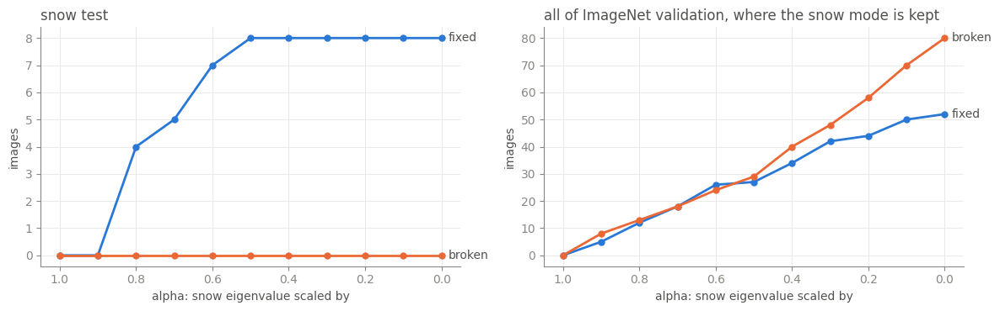

,snowy: fixed,snowy: broken,normal: fixed,normal: broken,ImageNet: fixed,ImageNet: broken
alpha,,,,,,
1.0,0,0,0,0,0,0
0.9,0,0,0,0,5,8
0.8,4,0,0,0,12,13
0.7,5,0,0,0,18,18
0.6,6,0,1,0,26,24
0.5,7,0,1,0,27,29
0.4,7,0,1,0,34,40
0.3,7,0,1,0,42,48
0.2,7,0,1,0,44,58


In [11]:
on = activity[:, SNOW_MODE] > 0
groups = {
    "snowy": (x[is_snowy, 0], y[is_snowy]),
    "normal": (x[~is_snowy, 0], y[~is_snowy]),
    "ImageNet": (val_x[on, 0], val_y[on]),
}
right = {group: classify(predict(kae, start)) == truth for group, (start, truth) in groups.items()}

rows = []
for alpha in np.linspace(1, 0, 11).round(1):
    edited = dampen(SNOW_MODE, alpha)
    row = {"alpha": alpha}
    for group, (start, truth) in groups.items():
        now = classify(predict(edited, start)) == truth
        row[f"{group}: fixed"] = int((~right[group] & now).sum())
        row[f"{group}: broken"] = int((right[group] & ~now).sum())
    rows.append(row)
damping = pd.DataFrame(rows).set_index("alpha")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
panels = [
    ("snow test", damping["snowy: fixed"] + damping["normal: fixed"], damping["snowy: broken"] + damping["normal: broken"]),
    ("all of ImageNet validation, where the snow mode is kept", damping["ImageNet: fixed"], damping["ImageNet: broken"]),
]
for ax, (title, fixed, broken) in zip(axes, panels):
    for values, label, color in [(fixed, "fixed", BLUE), (broken, "broken", ORANGE)]:
        ax.plot(values.index, values, color=color, lw=2, marker="o", ms=5)
        ax.annotate(label, (values.index[-1], values.iloc[-1]), xytext=(6, 0), textcoords="offset points", color=INK, va="center")
    ax.invert_xaxis()
    ax.set_xlabel("alpha: snow eigenvalue scaled by")
    ax.set_ylabel("images")
    ax.set_title(title, loc="left", color=INK)
fig.tight_layout()
plt.show()

damping

##### Which snowy images it fixes

Removing the mode (`alpha = 0`), the snowy images whose zero-shot answer goes from wrong to right.

Snowy images: 7 fixed, 0 broken, of 129
Normal images whose answer changes: 1 of 350


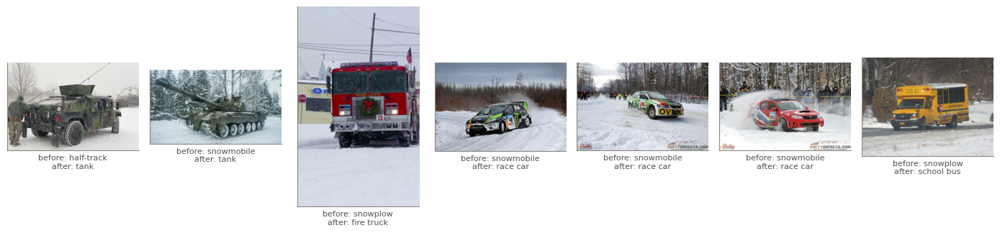

In [12]:
before_answers = classify(predict(kae, x[:, 0]))
removed = dampen(SNOW_MODE, 0.0)
after_answers = classify(predict(removed, x[:, 0]))

fixed = (is_snowy & (before_answers != y) & (after_answers == y)).nonzero()[:, 0]
broken = is_snowy & (before_answers == y) & (after_answers != y)
changed = ~is_snowy & (before_answers != after_answers)
print(f"Snowy images: {len(fixed)} fixed, {int(broken.sum())} broken, of {int(is_snowy.sum())}")
print(f"Normal images whose answer changes: {int(changed.sum())} of {int((~is_snowy).sum())}")

first_snowy = int((~is_snowy).sum())
shown = fixed[:8]
fig, axes = plt.subplots(1, len(shown), figsize=(2 * len(shown), 3.2))
for ax, index in zip(axes, shown.tolist()):
    image = Image.open(paths[index - first_snowy]).convert("RGB")
    image.thumbnail((256, 256))
    ax.imshow(np.asarray(image))
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)
    ax.set_xlabel(
        f"before: {class_names[before_answers[index]][:18]}\nafter: {class_names[after_answers[index]][:18]}",
        fontsize=8,
        color=INK,
    )
fig.tight_layout()
plt.show()

##### What the edit costs on the rest of ImageNet

K is shared by every image, so removing the snow mode changes every image where TopK keeps it, not only the snow test. Here are all 50,000 validation images.

In [13]:
on = activity[:, SNOW_MODE] > 0
truth = val_y[on]
before_val, after_val = classify(predict(kae, val_x[on, 0])), classify(predict(removed, val_x[on, 0]))
fixed_val = (before_val != truth) & (after_val == truth)
broken_val = (before_val == truth) & (after_val != truth)
print(f"Snow mode on for {int(on.sum())} of {len(val_y)} images: {int(fixed_val.sum())} fixed, {int(broken_val.sum())} broken")

pd.Series(Counter(class_names[c] for c in truth[broken_val].tolist())).sort_values(ascending=False).head(8).rename("broken").to_frame()

Snow mode on for 7372 of 50000 images: 52 fixed, 80 broken


,broken
ski,17
snowmobile,13
snowplow,10
wild boar,3
bobsleigh,2
balaclava ski mask,2
Australian Silky Terrier,1
ruler measuring stick,1


##### What dampening does, in CLIP's embedding space

PCA of the KAE's predicted embeddings for the 479 images. Each grey line joins a snowy image's prediction under K as trained (blue) to its prediction with the snow mode removed (orange). The large markers trace the average snowy prediction as `alpha` goes from 2 down to 0.

Median movement: snowy 0.154, normal 0.000


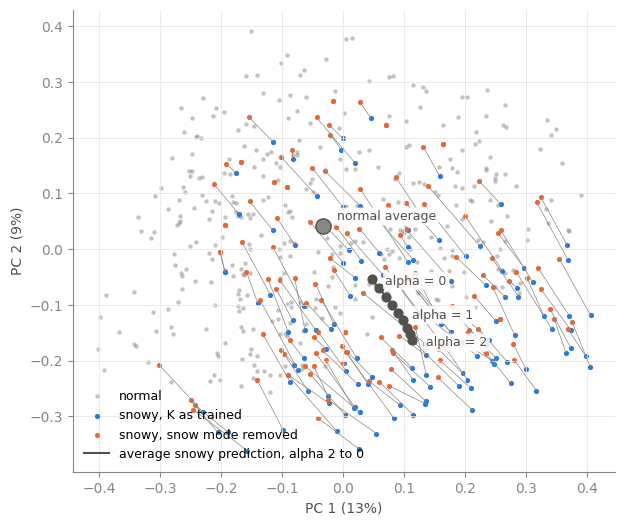

In [14]:
before, after = embed(predict(kae, x[:, 0])), embed(predict(removed, x[:, 0]))
moved = (after - before).norm(dim=-1)
print(f"Median movement: snowy {moved[is_snowy].median():.3f}, normal {moved[~is_snowy].median():.3f}")

snowy = is_snowy.numpy()
pca = PCA(2).fit(before.numpy())
before_2d, after_2d = pca.transform(before.numpy()), pca.transform(after.numpy())
path = np.stack([pca.transform(embed(predict(dampen(SNOW_MODE, alpha), snowy_x[:, 0])).mean(dim=0, keepdim=True).numpy())[0] for alpha in ALPHAS])

fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(*before_2d[~snowy].T, s=10, color=MUTED, alpha=0.5, lw=0, label="normal")
for i in snowy.nonzero()[0]:
    ax.plot([before_2d[i, 0], after_2d[i, 0]], [before_2d[i, 1], after_2d[i, 1]], color=MUTED, lw=0.5)
ax.scatter(*before_2d[snowy].T, s=14, color=BLUE, lw=0, label="snowy, K as trained")
ax.scatter(*after_2d[snowy].T, s=14, color=ORANGE, lw=0, label="snowy, snow mode removed")
ax.plot(*path.T, color=INK, lw=1.5, label="average snowy prediction, alpha 2 to 0")
ax.scatter(*path.T, s=40, color=INK, zorder=3)
for alpha, point in zip(ALPHAS, path):
    if alpha in (0.0, 1.0, 2.0):
        ax.annotate(
            f"alpha = {alpha:g}",
            point,
            xytext=(10, -4),
            textcoords="offset points",
            fontsize=9,
            color=INK,
            bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.85),
        )
ax.scatter(*before_2d[~snowy].mean(axis=0), s=120, color=MUTED, edgecolor=INK, zorder=3)
ax.annotate(
    "normal average",
    before_2d[~snowy].mean(axis=0),
    xytext=(10, 4),
    textcoords="offset points",
    fontsize=9,
    color=INK,
    bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.85),
)
ax.set_xlabel(f"PC 1 ({pca.explained_variance_ratio_[0]:.0%})")
ax.set_ylabel(f"PC 2 ({pca.explained_variance_ratio_[1]:.0%})")
ax.legend(loc="lower left", fontsize=9)
plt.show()

##### Other confounders: where CLIP itself fails

Snow makes CLIP itself fail on vehicles. To look for other factors like it, we use CLIP's zero-shot errors on ImageNet's 1.28 million training images. CLIP never trained on ImageNet, so these errors are honest, and each class has about 1,300 images. The KAE is used only to say which modes are on.

For each class and mode, we compare CLIP's accuracy on the class with the mode on against off. We keep snow-like candidates:
- the mode is on for at most 20% of all images, and spreads over at least 20 classes in its top 50;
- within the class, the mode is on for at least 50 images and at most 40% of them.

Pairs are ranked by a two-proportion z-score, keeping one pair per class.

In [15]:
train = torch.load(root / "imagenet" / "clip_cls_ViT-B-32_train_blocks_5_11.pt")
train_y = train["labels"]
train_on, train_answers = [], []
for batch in train["states"].split(20_000):
    batch = (batch - stats["mean"]) / stats["std"]
    train_on.append(get_activity(batch[:, 0]) > 0)
    train_answers.append(classify(batch[:, 1]))
train_on, train_answers = torch.cat(train_on), torch.cat(train_answers)
train_wrong = train_answers != train_y
del train
print(f"CLIP zero-shot on ImageNet's training images: {1 - train_wrong.double().mean():.3f}")

classes_in_top_50 = torch.tensor([len(set(val_y[activity[:, mode].topk(50).indices].tolist())) for mode in range(len(eigenvalues))])
eligible = (train_on.double().mean(dim=0) <= 0.2) & (classes_in_top_50 >= 20)

rows = []
for c in range(1_000):
    indices = (train_y == c).nonzero()[:, 0]
    on, wrong = train_on[indices], train_wrong[indices]
    n_on = on.sum(dim=0).double()
    n_off = len(indices) - n_on
    p_on = (on & wrong[:, None]).sum(dim=0) / n_on.clamp(min=1)
    p_off = (~on & wrong[:, None]).sum(dim=0) / n_off.clamp(min=1)
    pooled = (p_on * n_on + p_off * n_off) / len(indices)
    z = (p_on - p_off) / (pooled * (1 - pooled) * (1 / n_on.clamp(min=1) + 1 / n_off.clamp(min=1))).sqrt().clamp(min=1e-9)
    keep = eligible & (n_on >= 50) & (n_on <= 0.4 * len(indices))
    if not keep.any():
        continue

    mode = int(torch.where(keep, z, -torch.inf).argmax())
    mistakes = train_answers[indices[on[:, mode] & wrong]]
    rows.append(
        {
            "class": c,
            "mode": mode,
            "z": z[mode].item(),
            "images with mode on": int(n_on[mode]),
            "CLIP accuracy, mode on": 1 - p_on[mode].item(),
            "CLIP accuracy, mode off": 1 - p_off[mode].item(),
            "CLIP's usual wrong answer": class_names[int(torch.mode(mistakes).values)],
        }
    )

pairs = pd.DataFrame(rows).sort_values("z", ascending=False).reset_index(drop=True)
pairs.insert(0, "class name", pairs["class"].map(lambda c: class_names[c]))
pairs.head(12).round(3)

CLIP zero-shot on ImageNet's training images: 0.644


,class name,class,mode,z,images with mode on,"CLIP accuracy, mode on","CLIP accuracy, mode off",CLIP's usual wrong answer
0,baseball,429,353,24.449,333,0.207,0.902,baseball player
1,Pickelhaube,715,878,19.405,286,0.311,0.874,military uniform
2,airplane wing,908,935,19.048,311,0.222,0.806,military aircraft
3,gymnastic horizontal bar,602,829,12.862,179,0.302,0.773,swing
4,academic gown,400,218,11.779,256,0.508,0.848,graduation cap
5,computer mouse,673,694,11.587,278,0.241,0.631,desk
6,medicine cabinet,648,302,11.437,390,0.290,0.635,sliding door
7,combine harvester,595,950,11.228,391,0.248,0.587,tractor
8,home theater,598,642,11.064,440,0.393,0.710,entertainment center
9,red wine,966,118,10.840,391,0.522,0.814,wine bottle


The three strongest pairs: each mode's top validation images, then training images of the class that CLIP gets wrong while the mode is on, labelled with CLIP's answer.

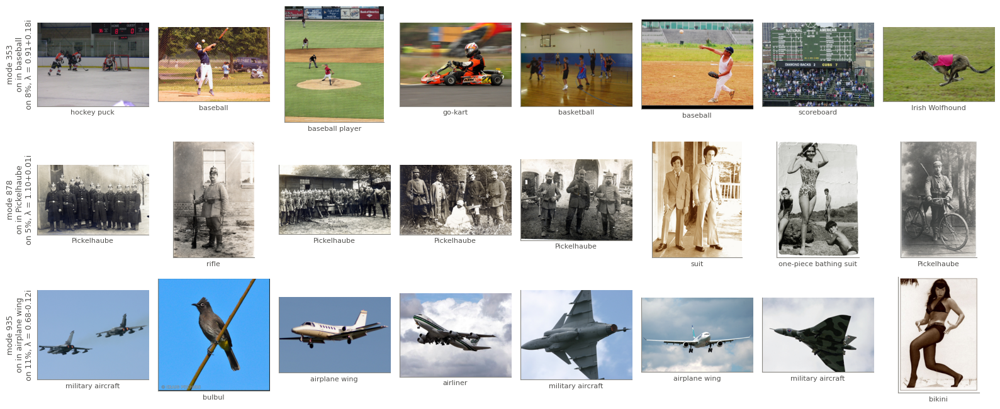

Loading dataset shards:   0%|          | 0/267 [00:00<?, ?it/s]

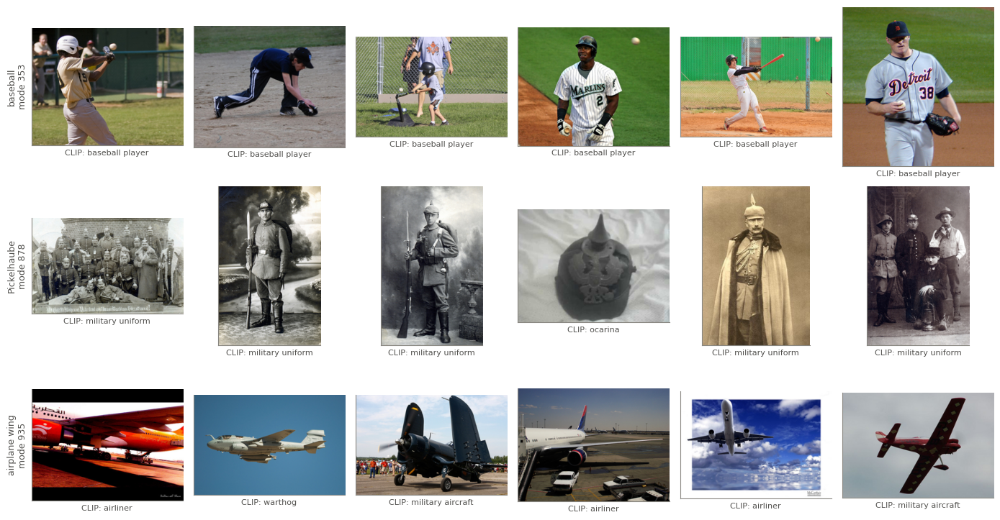

In [16]:
show_modes(list(pairs["mode"][:3]), [f"on in {name}" for name in pairs["class name"][:3]])

train_images = load_dataset("ILSVRC/imagenet-1k", split="train", cache_dir=os.getenv("DATASETS_CACHE"))
fig, axes = plt.subplots(3, 6, figsize=(14, 7.5))
for row, c, mode in zip(axes, pairs["class"][:3], pairs["mode"][:3]):
    indices = ((train_y == c) & train_on[:, mode] & train_wrong).nonzero()[:, 0][:6]
    for ax, index in zip(row, indices.tolist()):
        image = train_images[index]["image"].convert("RGB")
        image.thumbnail((256, 256))
        ax.imshow(np.asarray(image))
        ax.set_xticks([])
        ax.set_yticks([])
        ax.grid(False)
        ax.set_xlabel(f"CLIP: {class_names[train_answers[index]][:22]}", fontsize=8, color=INK)
    row[0].set_ylabel(f"{class_names[c]}\nmode {mode}", fontsize=9, color=INK)
fig.tight_layout()
plt.show()

Does removing the mode fix these errors in the KAE? For the top 20 pairs, on validation: fixes and breaks within the class, and everywhere else the mode is on.

In [17]:
rows = []
for c, mode in zip(pairs["class"][:20], pairs["mode"][:20]):
    on = activity[:, mode] > 0
    truth = val_y[on]
    before, after = classify(predict(kae, val_x[on, 0])), classify(predict(dampen(mode, 0.0), val_x[on, 0]))
    fixed, broken, target = (before != truth) & (after == truth), (before == truth) & (after != truth), truth == c
    rows.append(
        {
            "class": class_names[c],
            "mode": mode,
            "validation images": int(target.sum()),
            "class fixed": int((fixed & target).sum()),
            "class broken": int((broken & target).sum()),
            "elsewhere fixed": int((fixed & ~target).sum()),
            "elsewhere broken": int((broken & ~target).sum()),
        }
    )
removals = pd.DataFrame(rows)
print("Summed over the 20 pairs:", removals.drop(columns=["class", "mode"]).sum().to_dict())
removals

Summed over the 20 pairs: {'validation images': 305, 'class fixed': 3, 'class broken': 8, 'elsewhere fixed': 977, 'elsewhere broken': 1172}


,class,mode,validation images,class fixed,class broken,elsewhere fixed,elsewhere broken
0,baseball,353,18,0,1,33,38
1,Pickelhaube,878,45,1,3,56,64
2,airplane wing,935,21,0,0,25,32
3,gymnastic horizontal bar,829,8,0,0,46,39
4,academic gown,218,2,0,0,27,21
5,computer mouse,694,13,0,0,88,77
6,medicine cabinet,302,19,0,0,47,47
7,combine harvester,950,16,1,0,39,46
8,home theater,642,17,0,0,18,19
9,red wine,118,19,0,2,106,140


Most of these pairs aren't confounders in the snow sense. They are pictures with two labelled things in them: a baseball and a baseball player, a Pickelhaube on a soldier in an old photo, an academic gown and a graduation cap, an airplane wing on a military aircraft. CLIP's "wrong" answer is also in the picture, so removing the mode takes away context without adding evidence for the right class, and nothing gets fixed. Snow is different because snow is not an ImageNet class: it only distracts.